# Part 1 · Citi Bike 探索性分析
研究 2026 年 8–10 月的 20 个固定站点。每行代表一个站点小时。

## 1. Data Overview & Quality Check
我们检查了 2026 年 8–10 月 20 个站点的小时记录，共 44,160 条。数据完整覆盖了所有站点和小时，没有发现缺失、重复或净流量计算错误。约 5.5% 的站点小时既没有借车也没有还车，这些零交易记录保留在后续分析中

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

path = Path(r"E:\5206\group project\data.xlsx")
df = pd.read_excel(path, dtype={"station_id": str})
targets = ["departures", "arrivals"]
required = ["station_id", "hour", *targets, "net_flow"]
assert set(required).issubset(df.columns)
df["hour"] = pd.to_datetime(df["hour"], errors="coerce")
for col in [*targets, "net_flow"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
expected_hours = pd.date_range("2026-08-01", "2026-11-01", freq="h", inclusive="left")
grid = pd.MultiIndex.from_product([sorted(df.station_id.dropna().unique()), expected_hours])
observed = pd.MultiIndex.from_frame(df[["station_id", "hour"]])
checks = pd.Series({
    "missing_cells": df[required].isna().sum().sum(),
    "duplicates": observed.duplicated().sum(),
    "missing_station_hours": len(grid.difference(observed)),
    "unexpected_station_hours": len(observed.difference(grid)),
    "invalid_counts": ((df[targets] < 0) | (df[targets] % 1 != 0)).any(axis=1).sum(),
    "net_flow_errors": df.net_flow.ne(df.arrivals - df.departures).sum(),
})
print(f"{len(df):,} rows, {df.station_id.nunique()} stations, {df.hour.min()} to {df.hour.max()}")
display(df.head(), checks)
assert len(df) == 44160 and df.station_id.nunique() == 20 and checks.eq(0).all()
display(pd.DataFrame({"zero_rows": {**df[targets].eq(0).sum().to_dict(),
                                     "both_zero": df[targets].eq(0).all(axis=1).sum()}}
                    ).assign(percent=lambda x: 100*x.zero_rows/len(df)))
train = df.loc[df.hour.between("2026-08-08", "2026-10-01", inclusive="left")].copy()
EDA_SCOPE = "full"
assert EDA_SCOPE in {"full", "train"}
eda = (df if EDA_SCOPE == "full" else train).copy()
eda["clock"] = eda.hour.dt.hour
eda["weekday"] = eda.hour.dt.dayofweek
eda["day_type"] = np.where(eda.weekday < 5, "Weekday", "Weekend")
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
display(eda[targets + ["net_flow"]].describe().round(2))
print("Descriptive scope:", EDA_SCOPE, "| Training rows:", len(train))

44,160 rows, 20 stations, 2026-08-01 00:00:00 to 2026-10-31 23:00:00
Descriptive scope: full | Training rows: 25920


,station_id,hour,departures,arrivals,net_flow
0,5374.01,2026-08-01 00:00:00,27,22,-5
1,5374.01,2026-08-01 01:00:00,18,16,-2
2,5374.01,2026-08-01 02:00:00,10,7,-3
3,5374.01,2026-08-01 03:00:00,6,0,-6
4,5374.01,2026-08-01 04:00:00,2,1,-1


missing_cells               0
duplicates                  0
missing_station_hours       0
unexpected_station_hours    0
invalid_counts              0
net_flow_errors             0
dtype: int64

,zero_rows,percent
arrivals,3968,8.985507
both_zero,2440,5.525362
departures,4170,9.442935


,departures,arrivals,net_flow
count,44160.0,44160.00,44160.00
mean,18.7,18.43,-0.27
std,18.1,17.54,10.36
min,0.0,0.00,-141.00
25%,4.0,4.00,-3.00
50%,15.0,15.00,0.00
75%,28.0,28.00,3.00
max,190.0,161.00,105.00


**全期结果（默认范围）。** 20 个站点的 44,160 条小时记录覆盖完整，未发现缺失、重复或净流量计算错误。零交易小时是有效记录，后续分析中予以保留。

## 2. Overall Demand Distribution
我们用直方图和箱线图比较借车量和还车量。两者都呈右偏，中位数均为每站每小时 15 次，第 95 百分位均为 52 次。借车量最高的五条记录都出现在 6492.08 站的 17:00，最高达到每小时 190 次。（感觉这一部分好像作用不大，可以不放）

Highest departures observations
Highest arrivals observations


,mean,median,var,std,skew,max,p95,p99,zero_pct
departures,18.70,15.0,327.58,18.10,1.67,190.0,52.0,79.0,9.44
arrivals,18.43,15.0,307.75,17.54,1.40,161.0,52.0,74.0,8.99


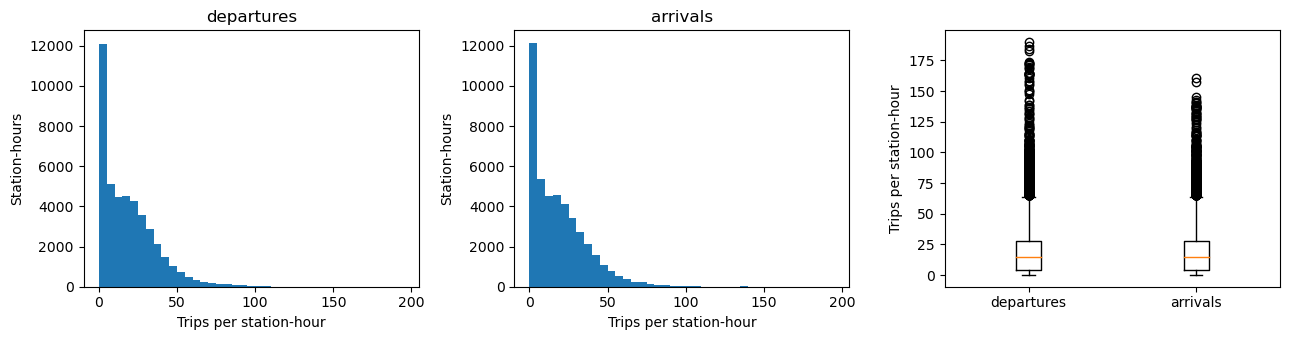

,station_id,hour,departures,arrivals,net_flow
34553,6492.08,2026-09-29 17:00:00,190,49,-141
34937,6492.08,2026-10-15 17:00:00,187,51,-136
35081,6492.08,2026-10-21 17:00:00,184,50,-134
34889,6492.08,2026-10-13 17:00:00,183,46,-137
34385,6492.08,2026-09-22 17:00:00,174,68,-106


,station_id,hour,departures,arrivals,net_flow
34208,6492.08,2026-09-15 08:00:00,60,161,101
9180,5905.12,2026-08-15 12:00:00,121,157,36
34256,6492.08,2026-09-17 08:00:00,67,145,78
34904,6492.08,2026-10-14 08:00:00,39,143,104
33368,6492.08,2026-08-11 08:00:00,45,141,96


In [2]:
demand = eda[targets]
stats = demand.agg(["mean", "median", "var", "std", "skew", "max"]).T
stats["p95"] = demand.quantile(.95)
stats["p99"] = demand.quantile(.99)
stats["zero_pct"] = demand.eq(0).mean() * 100
display(stats.round(2))
bins = np.arange(0, demand.max().max() + 6, 5)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, target in zip(axes, targets):
    ax.hist(demand[target], bins=bins)
    ax.set(title=target, xlabel="Trips per station-hour", ylabel="Station-hours")
axes[1].sharey(axes[0])
axes[2].boxplot([demand[t] for t in targets])
axes[2].set(xticks=[1, 2], xticklabels=targets, ylabel="Trips per station-hour")
plt.tight_layout()
plt.show()
for target in targets:
    print(f"Highest {target} observations")
    display(eda.nlargest(5, target)[required])

**全期结果（默认范围）。** 借还车量都呈右偏，中位数均为每站每小时 15 次，第 95 百分位均为 52 次。借车最大值达到 190 次，且借车量最高的五条记录都出现在 `6492.08` 站的 17 点。

## 3. Temporal Demand Patterns
比较了一天中不同时段、星期几以及周一至周五和周末的需求，并用日总量和 7 日移动平均观察变化。周一至周五的需求高峰偏向傍晚，周末偏向下午。按星期几看，周三平均借还量最高，周日最低。三个月的日均借车量相近，约为 8,950–9,024 次。

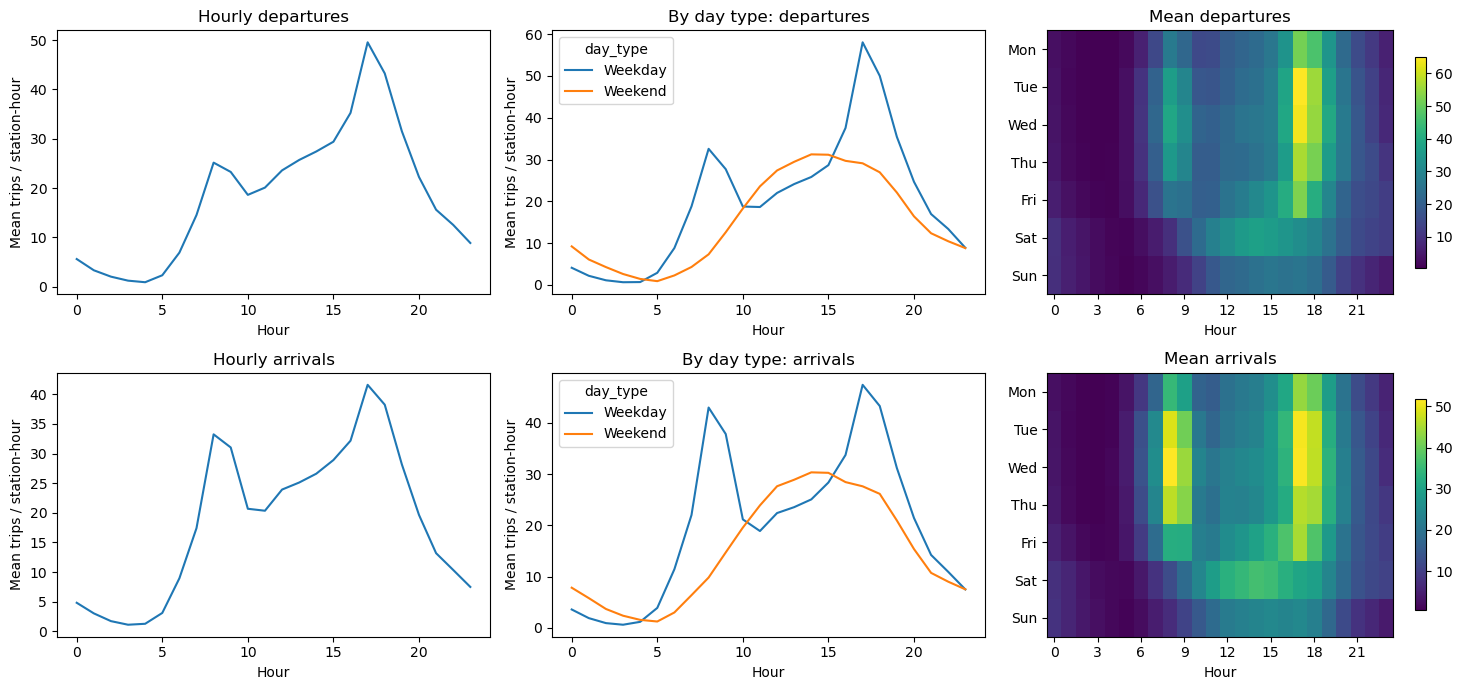

,departures,arrivals
weekday,,
Mon,17.58,17.19
Tue,20.76,20.38
Wed,21.72,21.37
Thu,20.64,20.45
Fri,19.78,19.65
Sat,18.02,17.85
Sun,12.43,12.17


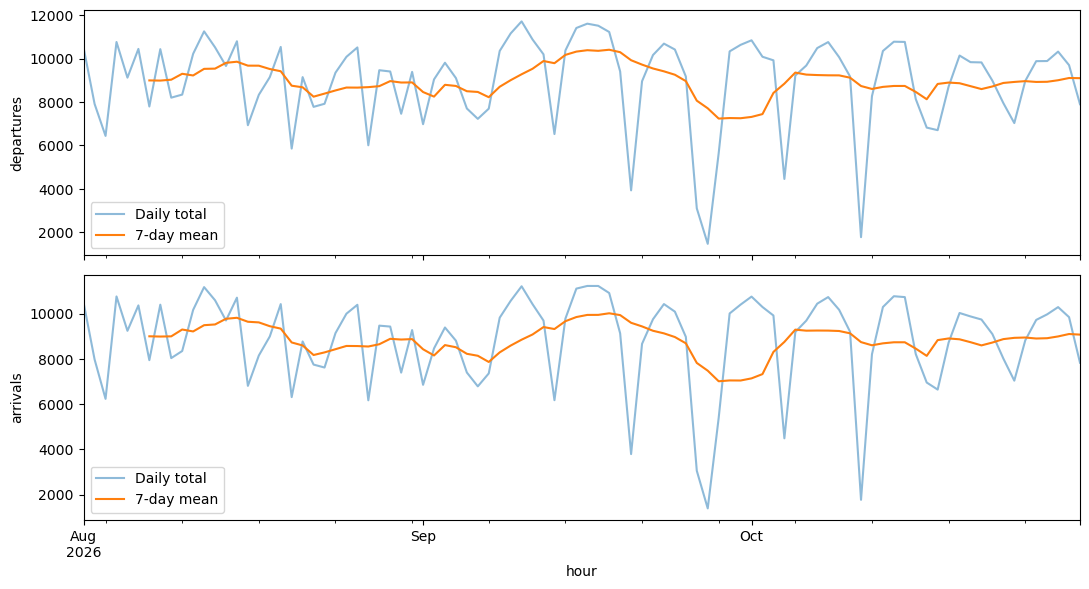

Monthly total          Trips per observed day         
           departures arrivals             departures arrivals
hour                                                          
2026-08        279747   278166                9024.10  8973.10
2026-09        268470   258233                8949.00  8607.77
2026-10        277467   277426                8950.55  8949.23

In [3]:
def heatmap(ax, data, title, xlabel, cmap="viridis", limits=None):
    limits = {} if limits is None else limits
    mesh = ax.imshow(data, aspect="auto", cmap=cmap, **limits)
    ax.set(title=title, xlabel=xlabel, yticks=range(len(data)), yticklabels=data.index)
    ticks = range(0, data.shape[1], 3)
    ax.set_xticks(list(ticks))
    ax.set_xticklabels([data.columns[i] for i in ticks])
    ax.figure.colorbar(mesh, ax=ax, shrink=.8)

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, target in zip(axes, targets):
    eda.groupby("clock")[target].mean().plot(ax=ax[0], title=f"Hourly {target}")
    eda.groupby(["clock", "day_type"])[target].mean().unstack().plot(ax=ax[1], title=f"By day type: {target}")
    matrix = eda.pivot_table(index="weekday", columns="clock", values=target).rename(index=dict(enumerate(days)))
    heatmap(ax[2], matrix, f"Mean {target}", "Hour")
    for line_ax in ax[:2]:
        line_ax.set(xlabel="Hour", ylabel="Mean trips / station-hour")
plt.tight_layout()
plt.show()

weekly = eda.groupby("weekday")[targets].mean().rename(index=dict(enumerate(days)))
display(weekly.round(2))
daily = eda.groupby(eda.hour.dt.normalize())[targets].sum()
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for ax, target in zip(axes, targets):
    daily[target].plot(ax=ax, alpha=.5, label="Daily total")
    daily[target].rolling(7).mean().plot(ax=ax, label="7-day mean")
    ax.set(ylabel=target)
    ax.legend()
plt.tight_layout()
plt.show()
month = daily.index.to_period("M")
display(pd.concat({"Monthly total": daily.groupby(month).sum(),
                   "Trips per observed day": daily.groupby(month).mean()}, axis=1).round(2))

 分时曲线显示，周末和周中的借还车曲线差别较大，周一至周五的需求高峰偏向傍晚，周末偏向下午。按星期几看，周三平均借还量最高，周日最低。三个月的日均借车量相近，约为 8,950–9,024 次。

## 4. Station-level Demand Analysis
按借车和还车的合计次数给站点排名，并用热力图和代表站点的分时曲线比较需求。`6140.05` 的借还总量最高。`6492.08` 的总量排第四，但它的借车量相对于自身平均水平波动更大。选了借还总量最高最低和中位数的三个站点画出了时段借还图进行分析。

departures                ...       arrivals combined
                  sum   mean    std  ...    cv       cv      sum
station_id                           ...                        
6140.05         53562  24.26  22.12  ...  0.91     0.86   107185
6233.04         51242  23.21  23.97  ...  1.03     0.93   102434
6331.01         45400  20.56  17.12  ...  0.83     0.87    90391
6492.08         44183  20.01  26.09  ...  1.30     1.17    88553
6948.1          44227  20.03  18.66  ...  0.93     0.93    88206
5905.12         43453  19.68  16.69  ...  0.85     0.82    86974
6432.09         42728  19.35  21.17  ...  1.09     1.04    85738
5980.1          46963  21.27  20.36  ...  0.96     1.12    82904
5905.14         41259  18.69  15.73  ...  0.84     0.81    82586
6173.08         40293  18.25  20.09  ...  1.10     0.97    80646
6072.06         39551  17.91  14.05  ...  0.78     0.86    79319
6364.07         39752  18.00  15.35  ...  0.85     0.93    78789
5492.05         39086  17.70  16.06  ...  0.91     0.89    78258
6726.01         38706  17.53  14.16  ...  0.81     0.91    77213
6912.01         37734  17.09  19.56  ...  1.14     1.14    74792
6459.07         36950  16.73  15.39  ...  0.92     0.92    73955
5763.03         36263  16.42  12.60  ...  0.77     0.87    72534
5374.01         35781  16.21  12.18  ...  0.75     0.82    71658
5712.03         35312  15.99  13.30  ...  0.83     0.85    70665
6822.09         33239  15.05  16.52  ...  1.10     0.93    66709

[20 rows x 9 columns]

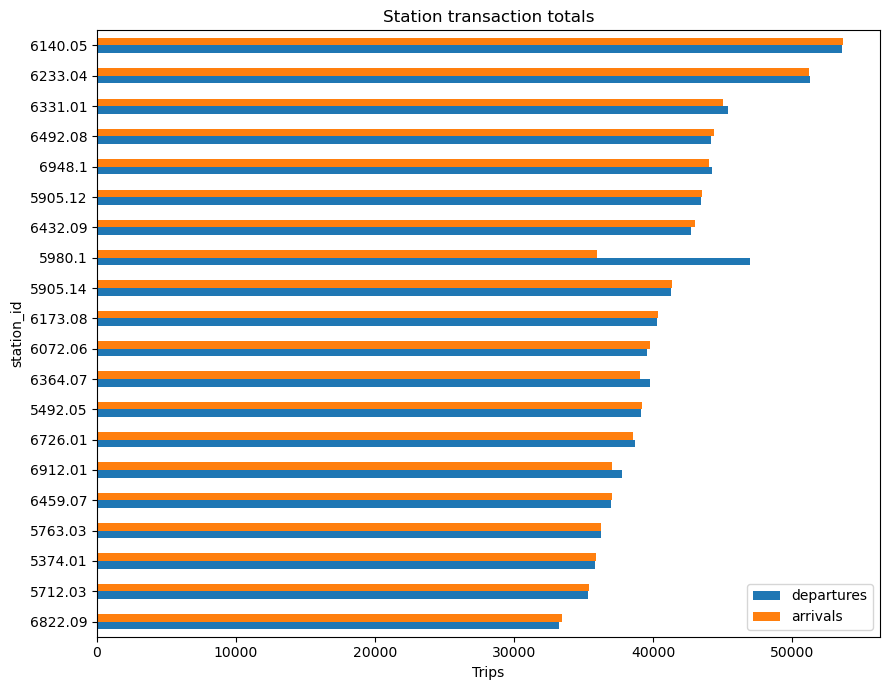

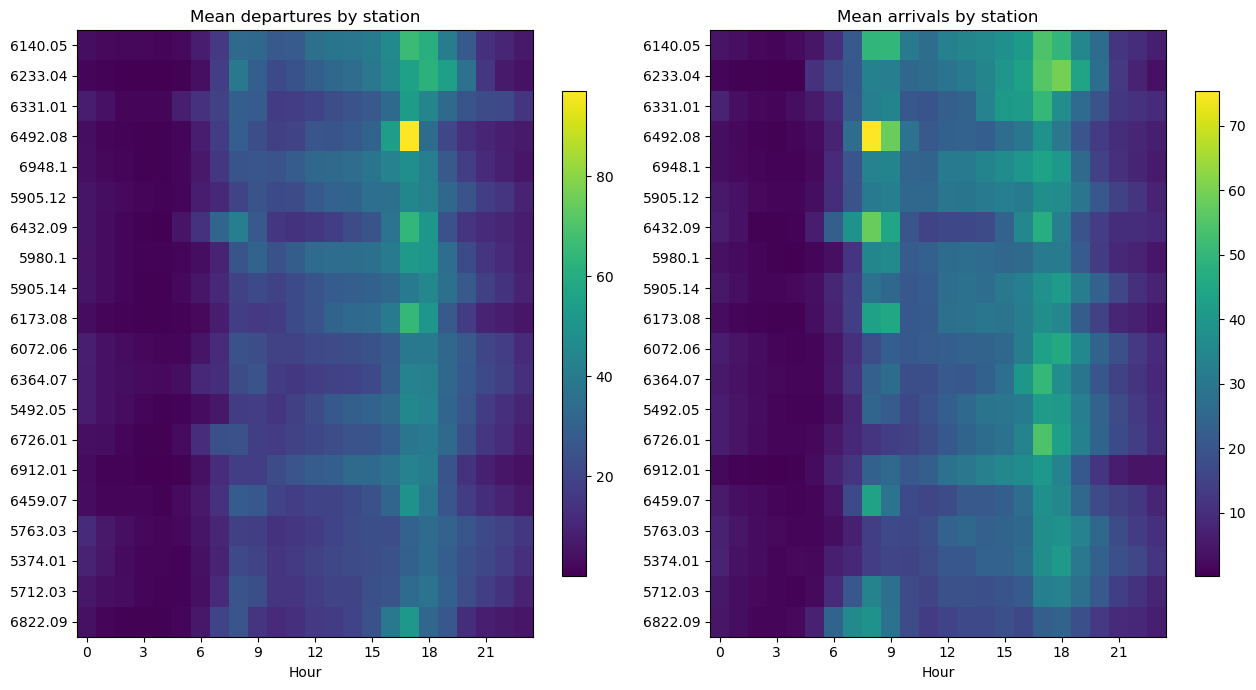

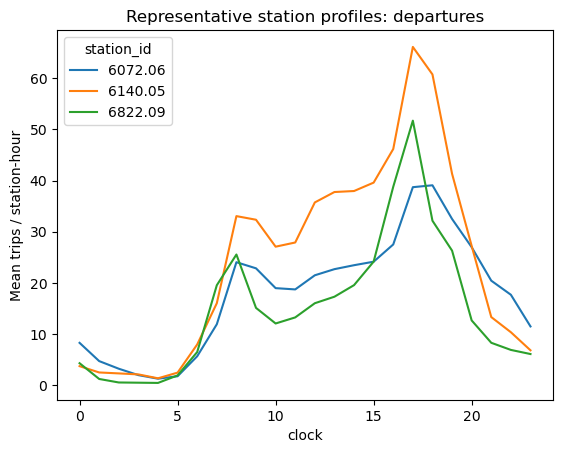

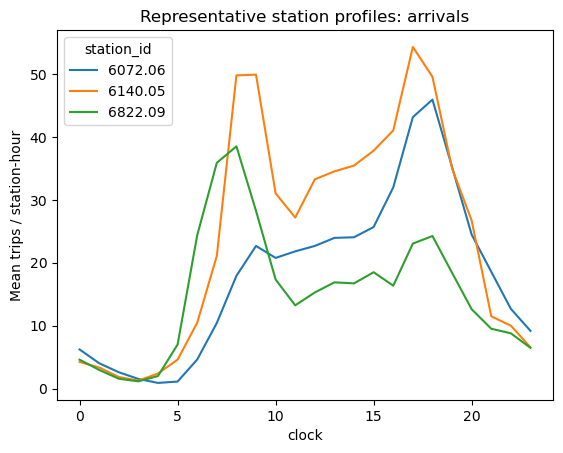

In [4]:
group = eda.groupby("station_id")[targets]
station = group.agg(["sum", "mean", "std"])
for target in targets:
    station[(target, "cv")] = station[(target, "std")] / station[(target, "mean")].replace(0, np.nan)
station[("combined", "sum")] = group.sum().sum(axis=1)
station = station.sort_values(("combined", "sum"), ascending=False)
display(station.round(2))
group.sum().reindex(station.index).iloc[::-1].plot.barh(figsize=(9, 7), title="Station transaction totals")
plt.xlabel("Trips")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 7))
for ax, target in zip(axes, targets):
    matrix = eda.pivot_table(index="station_id", columns="clock", values=target).reindex(station.index)
    heatmap(ax, matrix, f"Mean {target} by station", "Hour")
plt.tight_layout()
plt.show()
examples = station.index[[0, len(station)//2, -1]]
profile = eda.loc[eda.station_id.isin(examples)].groupby(["clock", "station_id"])[targets].mean()
for target in targets:
    profile[target].unstack().plot(title=f"Representative station profiles: {target}", ylabel="Mean trips / station-hour")
    plt.show()

**全期结果（默认范围）。** `6140.05` 的借还车总量最高。`6492.08` 总量排第四，但借车量的变异系数约为 1.30，高于 `6140.05` 的 0.91，说明两站的需求规模和相对波动有所不同。

## 5. Departure–Arrival Relationship
计算了同站同小时借车量和还车量的相关性，并比较了各站点的分时净流量。借还车量总体呈较强正相关，Pearson 相关系数为 0.83。部分站点在特定时段仍有明显的净流出，例如 6492.08 在周一至周五 17:00–18:00 平均净流出约 82 辆。

Pooled, same-hour correlation


pearson     0.831
spearman    0.906
dtype: float64

,pearson,spearman,mean_net,mean_abs_net
5980.1,0.753,0.837,-4.992,8.810
6364.07,0.870,0.885,-0.324,5.464
6912.01,0.902,0.942,-0.306,4.932
6331.01,0.826,0.848,-0.185,6.805
6948.1,0.918,0.941,-0.112,4.731
6726.01,0.850,0.880,-0.090,5.202
6233.04,0.937,0.936,-0.023,5.226
5763.03,0.876,0.893,0.004,4.756
5712.03,0.865,0.892,0.019,4.739
6459.07,0.871,0.922,0.025,4.875


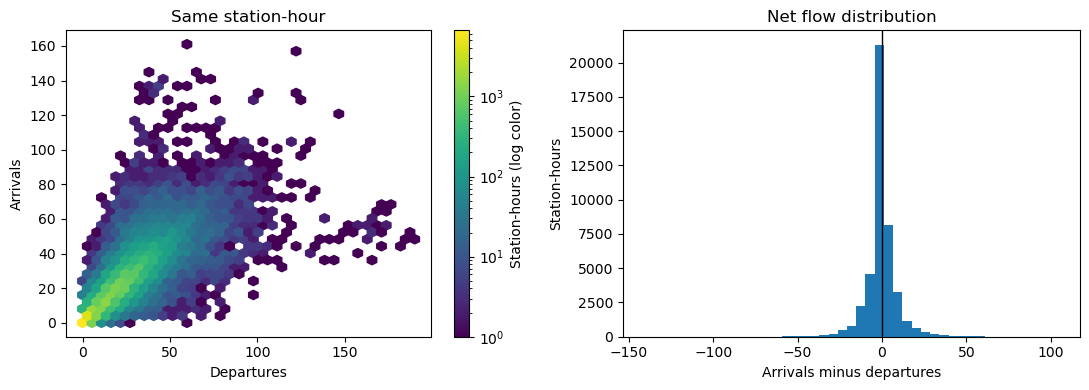

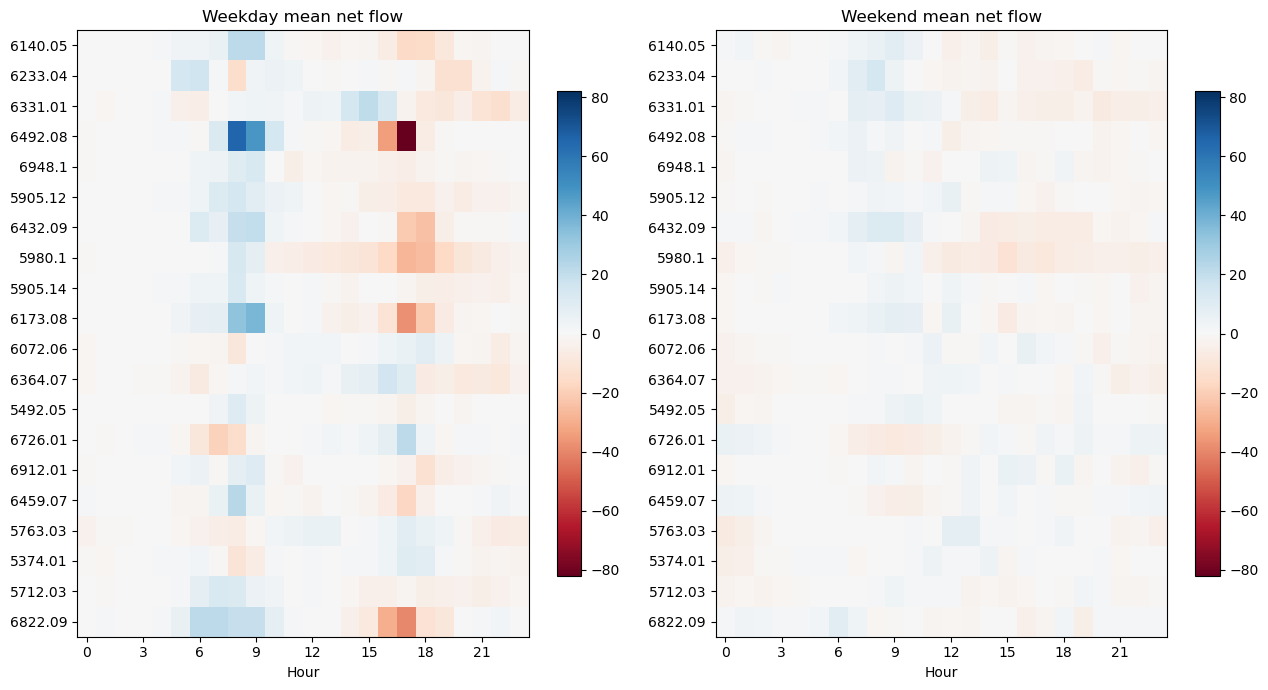

,departures,arrivals,net_flow
station_id,,,
6492.08,128.55,46.45,-82.11
6822.09,67.06,27.45,-39.62
6173.08,80.08,42.49,-37.58
5980.1,61.83,34.46,-27.37
6432.09,81.86,60.42,-21.45
6459.07,60.38,43.12,-17.26
6140.05,78.22,62.55,-15.66
5905.12,50.55,42.37,-8.18
6948.1,52.43,46.66,-5.77


In [5]:
methods = ["pearson", "spearman"]
print("Pooled, same-hour correlation")
display(pd.Series({m: eda.departures.corr(eda.arrivals, method=m) for m in methods}).round(3))
station_relationship = pd.DataFrame.from_dict({
    key: {**{m: g.departures.corr(g.arrivals, method=m) for m in methods},
          "mean_net": g.net_flow.mean(), "mean_abs_net": g.net_flow.abs().mean()}
    for key, g in eda.groupby("station_id")
}, orient="index").sort_values("mean_net")
display(station_relationship.round(3))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
density = axes[0].hexbin(eda.departures, eda.arrivals, gridsize=35, bins="log", mincnt=1)
fig.colorbar(density, ax=axes[0], label="Station-hours (log color)")
axes[0].set(xlabel="Departures", ylabel="Arrivals", title="Same station-hour")
axes[1].hist(eda.net_flow, bins=45)
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set(xlabel="Arrivals minus departures", ylabel="Station-hours", title="Net flow distribution")
plt.tight_layout()
plt.show()

net_profiles = {label: block.pivot_table(index="station_id", columns="clock", values="net_flow").reindex(station.index)
                for label, block in eda.groupby("day_type")}
bound = max(1, max(np.abs(matrix.to_numpy()).max() for matrix in net_profiles.values()))
fig, axes = plt.subplots(1, 2, figsize=(13, 7))
for ax, (label, matrix) in zip(axes, net_profiles.items()):
    heatmap(ax, matrix, f"{label} mean net flow", "Hour", "RdBu", {"vmin": -bound, "vmax": bound})
plt.tight_layout()
plt.show()
focus = (eda.loc[(eda.day_type == "Weekday") & (eda.clock == 17)]
         .groupby("station_id")[targets + ["net_flow"]].mean().sort_values("net_flow"))
display(focus.round(2))

**全期结果（默认范围）。** 同站同小时的借还车量总体呈较强正相关（Pearson 0.83，Spearman 0.91）。但分时净流量仍有明显差异，例如 `6492.08` 在周一至周五 17:00–18:00 平均净流出约 82 辆。

## 6. Temporal Dependence & Count Characteristics
只用训练期数据，按站点检查借还车量与不同滞后小时的关系。借还车量在 1、24 和 168 小时滞后下的相关性较强，2、3 小时也有正相关，6 小时的相关性接近零。（后面建模这几个滞后都用了）

,1,2,3,6,24,168
target,,,,,,
arrivals,0.803,0.627,0.428,-0.025,0.744,0.792
departures,0.788,0.601,0.399,-0.051,0.731,0.798


,,1,2,3,6,24,168
target,station,,,,,,
departures,5374.01,0.779,0.605,0.439,-0.066,0.697,0.752
arrivals,5374.01,0.801,0.647,0.473,-0.042,0.744,0.768
departures,5492.05,0.833,0.675,0.522,0.011,0.743,0.797
arrivals,5492.05,0.800,0.630,0.481,0.011,0.720,0.792
departures,5712.03,0.775,0.540,0.337,-0.118,0.720,0.798
arrivals,5712.03,0.738,0.437,0.199,-0.164,0.699,0.790
departures,5763.03,0.783,0.625,0.456,-0.045,0.665,0.721
arrivals,5763.03,0.810,0.632,0.458,0.000,0.700,0.754
departures,5905.12,0.836,0.690,0.512,0.023,0.691,0.794


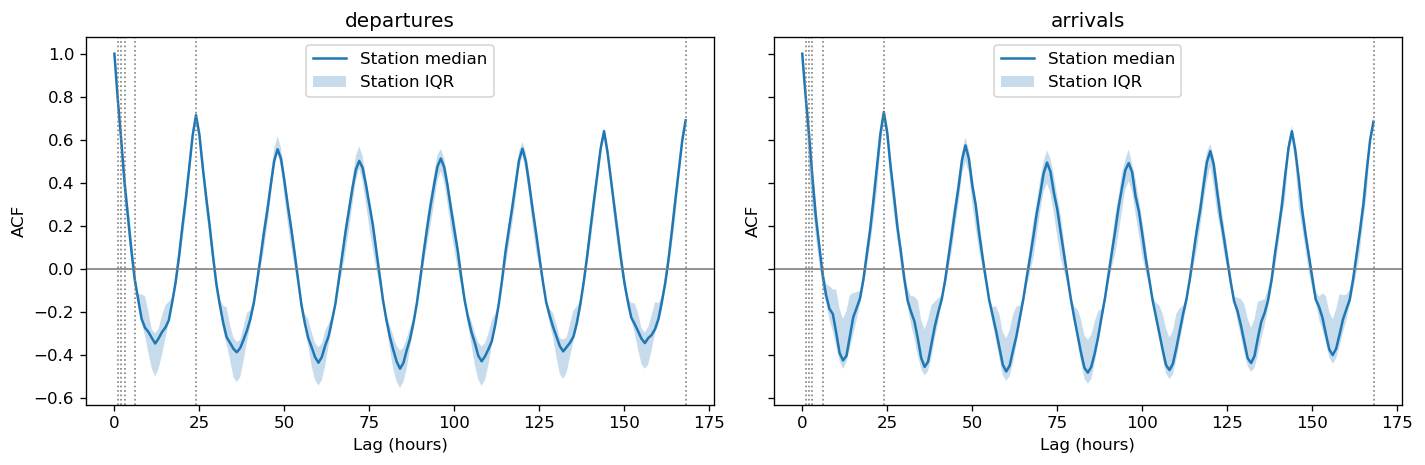

In [6]:
lags = [1, 2, 3, 6, 24, 168]
acf_rows = []
lag_rows = []
for key, block in train.sort_values("hour").groupby("station_id"):
    assert block.hour.diff().dropna().eq(pd.Timedelta(hours=1)).all()
    for target in targets:
        series = block[target].reset_index(drop=True)
        centered = series.to_numpy() - series.mean()
        full = np.correlate(centered, centered, mode="full")
        acf = full[len(series)-1:len(series)+168]
        acf_rows.append(pd.Series(acf / acf[0] if acf[0] else np.full(169, np.nan), name=(target, key)))
        lag_rows.append({"target": target, "station": key, **{lag: series.autocorr(lag) for lag in lags}})
acf_table = pd.DataFrame(acf_rows)
lag_table = pd.DataFrame(lag_rows).set_index(["target", "station"])
display(lag_table.groupby(level="target").median().round(3), lag_table.round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, target in zip(axes, targets):
    panel = acf_table.loc[target]
    x = panel.columns.to_numpy(dtype=float)
    ax.plot(x, panel.median().to_numpy(), label="Station median")
    ax.fill_between(x, panel.quantile(.25).to_numpy(), panel.quantile(.75).to_numpy(), alpha=.25, label="Station IQR")
    ax.axhline(0, color="gray", linewidth=1)
    for lag in lags:
        ax.axvline(lag, color="gray", linestyle=":", linewidth=1)
    ax.set(title=target, xlabel="Lag (hours)", ylabel="ACF")
    ax.legend()
plt.tight_layout()
plt.show()

**训练期结果。** 2、3、6 小时的逐站相关中位数，借车分别为 0.60、0.40、-0.05，还车分别为 0.63、0.43、-0.02。这些数值描述短期相关，预测价值由验证集评估。

### 均值、方差和 Poisson 初筛
逐站比较均值和方差，再按站点、星期几和小时分组，减少混合时段带来的差异。每组至少 5 条记录，且均值大于零才计算方差均值比。比值偏大是初筛信号。条件 Poisson 假设要结合拟合后残差诊断判断。

departures: 3,340 groups, median variance/mean = 1.96
arrivals: 3,342 groups, median variance/mean = 2.00


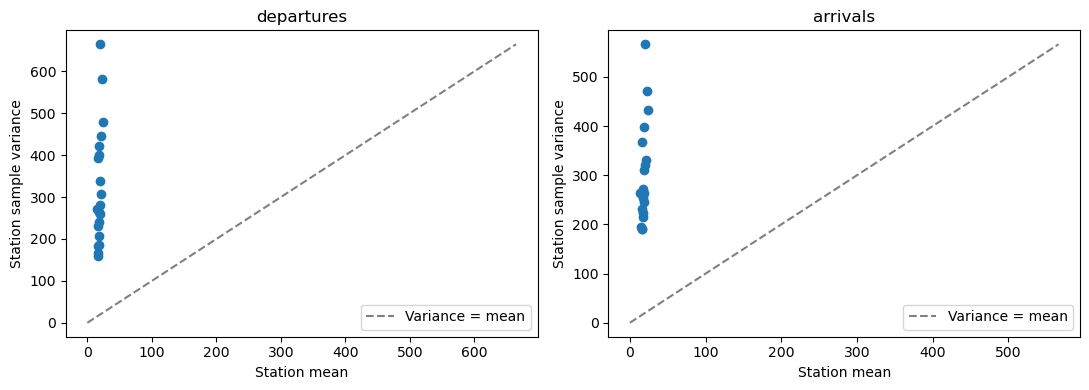

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, target in zip(axes, targets):
    mv = train.groupby("station_id")[target].agg(["mean", "var"])
    ax.scatter(mv["mean"], mv["var"])
    ceiling = mv.to_numpy().max()
    ax.plot([0, ceiling], [0, ceiling], "--", color="gray", label="Variance = mean")
    ax.set(title=target, xlabel="Station mean", ylabel="Station sample variance")
    ax.legend()
    same_slot = train.groupby(["station_id", train.hour.dt.dayofweek, train.hour.dt.hour])[target].agg(["size", "mean", "var"])
    eligible = same_slot.loc[(same_slot["size"] >= 5) & (same_slot["mean"] > 0)]
    ratio = eligible["var"] / eligible["mean"]
    print(f"{target}: {len(ratio):,} groups, median variance/mean = {ratio.median():.2f}")
plt.tight_layout()
plt.show()

**训练期结果。** 按站点、星期几和小时分组后，借车和还车的方差均值比中位数分别为 1.96 和 2.00。这提示可能存在过度离散，是否符合条件 Poisson 假设还需结合模型残差判断。